In [1]:
# =================================================================================================
#                         Marketing Campaign Performance Insights
# =================================================================================================

# Import Required Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the Dataset

url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"

df = pd.read_csv(url)

# First Five Rows
df.head()

,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
0,1,TechCorp,Email,Women 25-34,30 days,Facebook,5.294194,9344,62.94,Houston,English,3045,67836,5,Tech Enthusiasts,01-01-2023
1,2,Innovate Industries,Influencer,Women 35-44,45 days,Google Ads,3.326375,8783,10.67,"Washington, D.C.",German,1944,66361,4,Foodies,01-01-2023
2,3,NexGen Systems,Social Media,Women 25-34,45 days,Instagram,4.056375,9111,73.20,Miami,Spanish,3156,86240,8,Fashionistas,01-01-2023
3,4,Innovate Industries,Email,Women 25-34,45 days,Instagram,4.496375,7420,60.92,Seattle,Spanish,2388,58251,6,Foodies,01-01-2023
4,5,Data Tech Solutions,Influencer,Men 25-34,30 days,Google Ads,4.405930,2146,138.82,Chicago,English,1025,34407,5,Tech Enthusiasts,01-01-2023


In [3]:
# Basic Structure of the Dataset

print("Rows and Columns:", df.shape)

df.info()

Rows and Columns: (22029, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22029 entries, 0 to 22028
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Campaign_ID       22029 non-null  int64  
 1   Company           22029 non-null  object 
 2   Campaign_Type     22029 non-null  object 
 3   Target_Audience   22029 non-null  object 
 4   Duration          22029 non-null  object 
 5   Channel_Used      22029 non-null  object 
 6   Conversion_Rate   22029 non-null  float64
 7   Acquisition_Cost  22029 non-null  int64  
 8   ROI               22029 non-null  float64
 9   Location          22029 non-null  object 
 10  Language          22029 non-null  object 
 11  Clicks            22029 non-null  int64  
 12  Impressions       22029 non-null  int64  
 13  Engagement_Score  22029 non-null  int64  
 14  Customer_Segment  22029 non-null  object 
 15  Date              22029 non-null  object 
dtypes: float64

In [4]:
# Descriptive Statistics

df.describe()

,Campaign_ID,Conversion_Rate,Acquisition_Cost,ROI,Clicks,Impressions,Engagement_Score
count,22029.000000,22029.000000,22029.000000,22029.000000,22029.000000,22029.000000,22029.000000
mean,11015.000000,4.757232,5522.740842,182.863648,2223.807572,50610.402787,6.582323
std,6359.368876,0.960393,2597.666260,301.619721,1394.166380,28542.979123,1.458804
min,1.000000,2.015723,1000.000000,-98.300000,30.000000,1001.000000,4.000000
25%,5508.000000,4.130705,3286.000000,-4.080000,1067.000000,25804.000000,5.000000
50%,11015.000000,4.761527,5525.000000,93.650000,2088.000000,50858.000000,7.000000
75%,16522.000000,5.429335,7766.000000,247.310000,3212.000000,75165.000000,8.000000
max,22029.000000,7.469907,9999.000000,3109.790000,6887.000000,99999.000000,9.000000


In [5]:
# Data Exploration

# Number of unique Campaign_ID values
print("Number of Unique Campaign_ID values:")
print(df["Campaign_ID"].nunique())

print("\nUnique Location values:")
print(df["Location"].unique())

print("\nUnique Customer_Segment values:")
print(df["Customer_Segment"].unique())

print("\nCampaign_Type counts:")
print(df["Campaign_Type"].value_counts())

print("\nChannel_Used counts:")
print(df["Channel_Used"].value_counts())

Number of Unique Campaign_ID values:
22029

Unique Location values:
['Houston' 'Washington, D.C.' 'Miami' 'Seattle' 'Chicago' 'Los Angeles'
 'Atlanta' 'Dallas' 'New York' 'San Francisco']

Unique Customer_Segment values:
['Tech Enthusiasts' 'Foodies' 'Fashionistas' 'Outdoor Adventurers'
 'Health & Wellness']

Campaign_Type counts:
Campaign_Type
Display         4450
Search          4441
Social Media    4412
Email           4388
Influencer      4338
Name: count, dtype: int64

Channel_Used counts:
Channel_Used
Facebook      3742
Google Ads    3694
Website       3688
Instagram     3649
YouTube       3632
Email         3624
Name: count, dtype: int64


In [6]:
# Data Preparation

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

# Extract numeric Duration values
df["Duration_Days"] = df["Duration"].str.extract(r"(\d+)").astype(float)

print("Data preparation completed.")
print("\nDate data type:", df["Date"].dtype)
print("Duration_Days data type:", df["Duration_Days"].dtype)

Data preparation completed.

Date data type: datetime64[ns]
Duration_Days data type: float64


In [7]:
# Set Visualization Style

sns.set_theme(style="whitegrid")

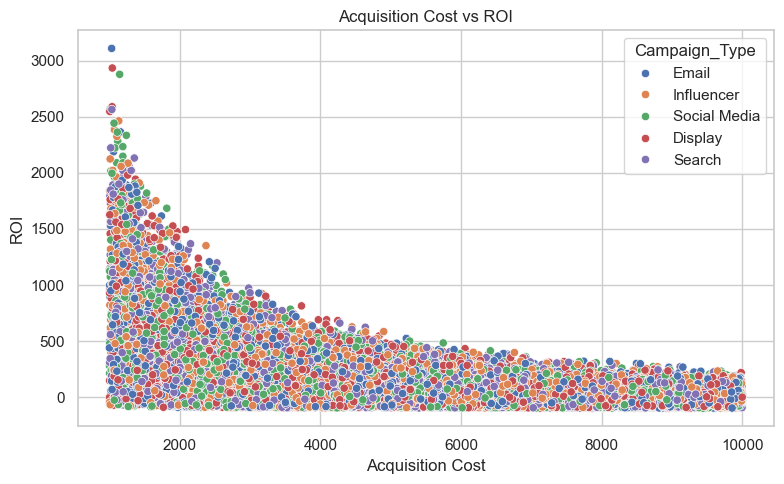

In [8]:
# Campaign Performance Analysis
# Acquisition Cost vs ROI

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Acquisition_Cost",
    y="ROI",
    hue="Campaign_Type"
)

plt.title("Acquisition Cost vs ROI")
plt.xlabel("Acquisition Cost")
plt.ylabel("ROI")
plt.tight_layout()
plt.show()

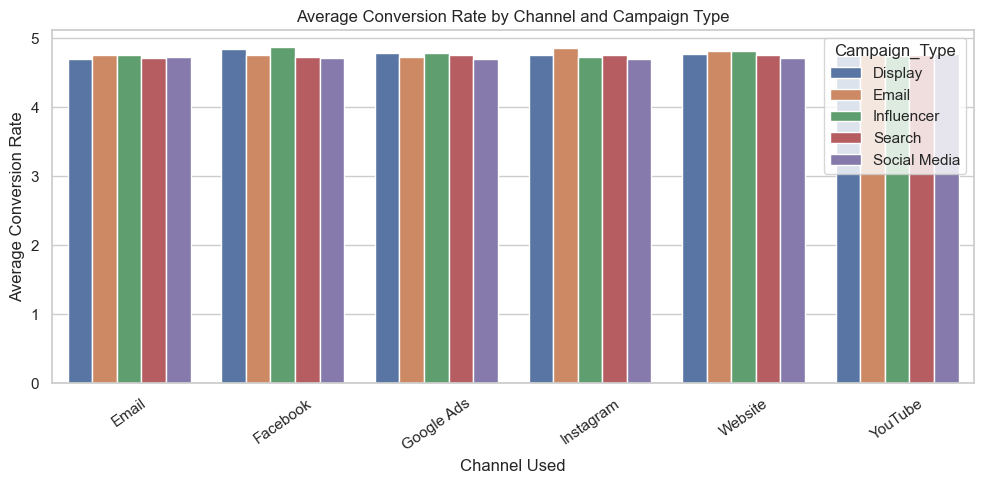

In [9]:
# Average Conversion Rate by Channel and Campaign Type

avg_conv = (
    df.groupby(["Channel_Used", "Campaign_Type"])["Conversion_Rate"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=avg_conv,
    x="Channel_Used",
    y="Conversion_Rate",
    hue="Campaign_Type"
)

plt.title("Average Conversion Rate by Channel and Campaign Type")
plt.xlabel("Channel Used")
plt.ylabel("Average Conversion Rate")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

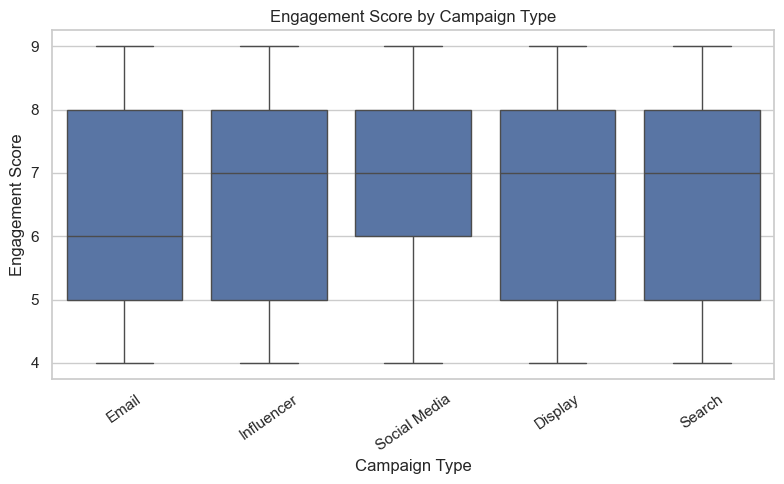

In [10]:
# Engagement Score by Campaign Type

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Campaign_Type",
    y="Engagement_Score"
)

plt.title("Engagement Score by Campaign Type")
plt.xlabel("Campaign Type")
plt.ylabel("Engagement Score")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

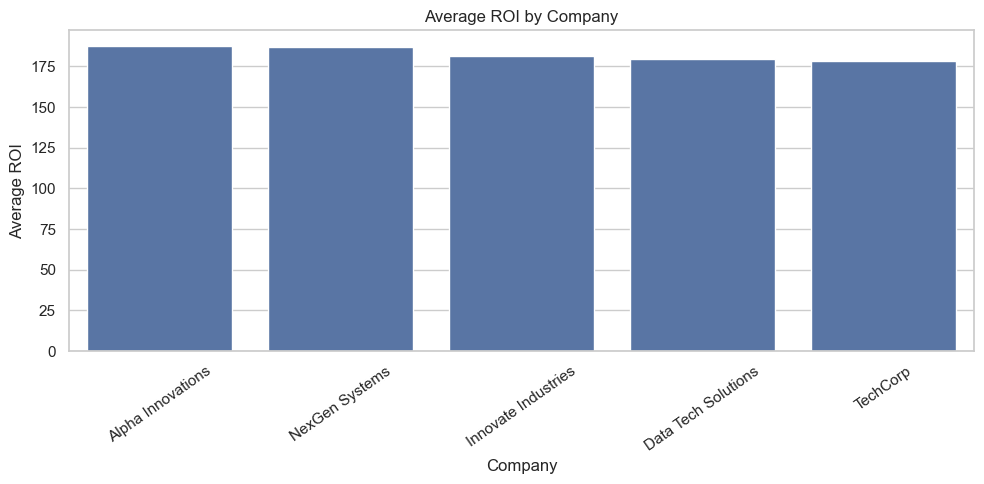

In [11]:
# Average ROI by Company

company_roi = (
    df.groupby("Company")["ROI"]
    .mean()
    .reset_index()
    .sort_values("ROI", ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=company_roi,
    x="Company",
    y="ROI"
)

plt.title("Average ROI by Company")
plt.xlabel("Company")
plt.ylabel("Average ROI")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

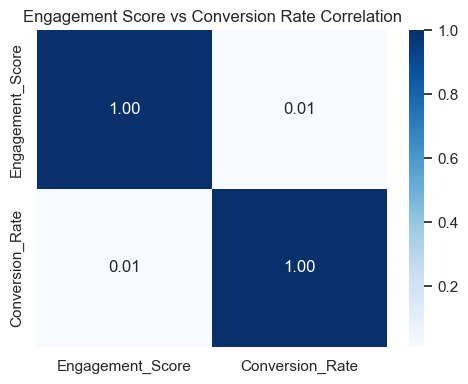

In [12]:
# Correlation Between Engagement Score and Conversion Rate

correlation_data = df[
    ["Engagement_Score", "Conversion_Rate"]
].corr()

plt.figure(figsize=(5, 4))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Engagement Score vs Conversion Rate Correlation")
plt.tight_layout()
plt.show()

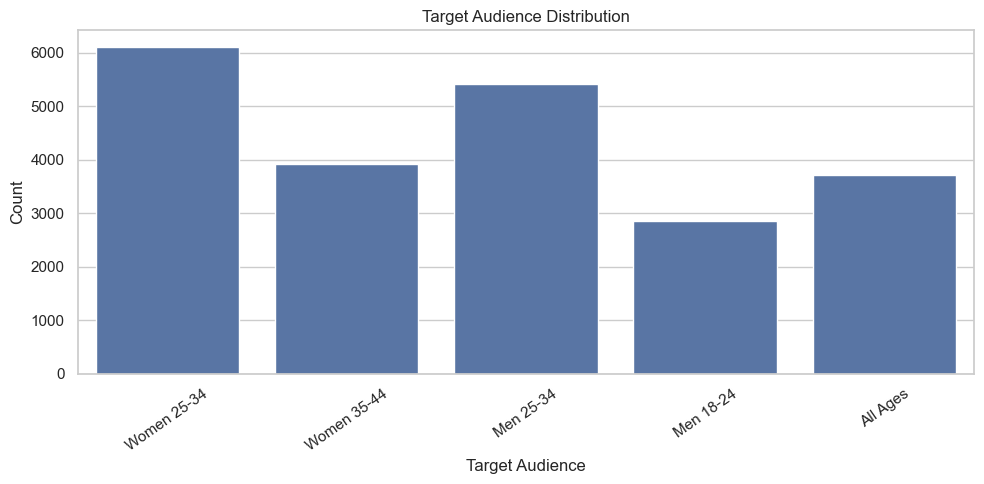

In [13]:
# Customer Segmentation Analysis
# Target Audience Distribution

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Target_Audience"
)

plt.title("Target Audience Distribution")
plt.xlabel("Target Audience")
plt.ylabel("Count")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

Highest Conversion Customer Segment for Each Language:
    Language   Customer_Segment  Conversion_Rate
4    English   Tech Enthusiasts         5.022731
7     French  Health & Wellness         4.689704
11    German            Foodies         4.705430
17  Mandarin  Health & Wellness         4.756125
21   Spanish            Foodies         4.663610


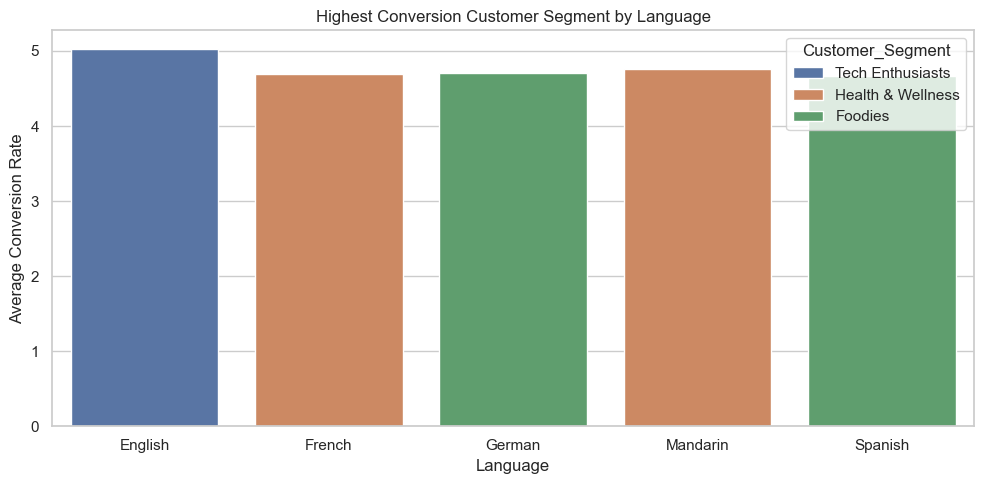

In [14]:
# Highest Conversion Customer Segment by Language

segment_conversion = (
    df.groupby(
        ["Language", "Customer_Segment"]
    )["Conversion_Rate"]
    .mean()
    .reset_index()
)

best_segment = segment_conversion.loc[
    segment_conversion.groupby("Language")["Conversion_Rate"].idxmax()
]

print("Highest Conversion Customer Segment for Each Language:")
print(best_segment)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=best_segment,
    x="Language",
    y="Conversion_Rate",
    hue="Customer_Segment"
)

plt.title("Highest Conversion Customer Segment by Language")
plt.xlabel("Language")
plt.ylabel("Average Conversion Rate")
plt.tight_layout()
plt.show()

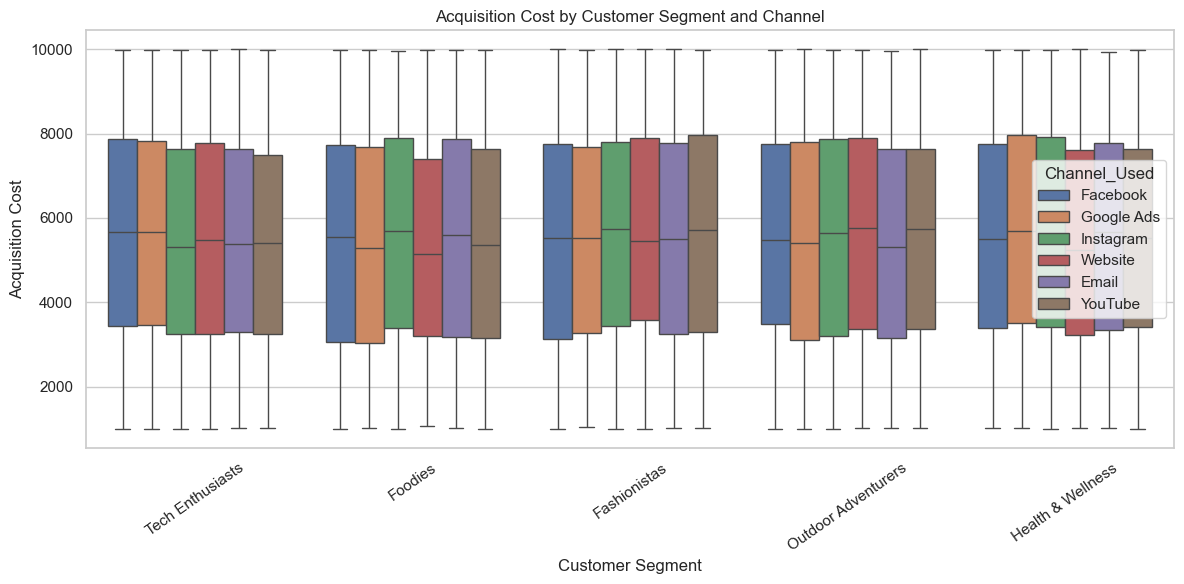

In [15]:
# Acquisition Cost by Customer Segment and Channel

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Customer_Segment",
    y="Acquisition_Cost",
    hue="Channel_Used"
)

plt.title("Acquisition Cost by Customer Segment and Channel")
plt.xlabel("Customer Segment")
plt.ylabel("Acquisition Cost")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

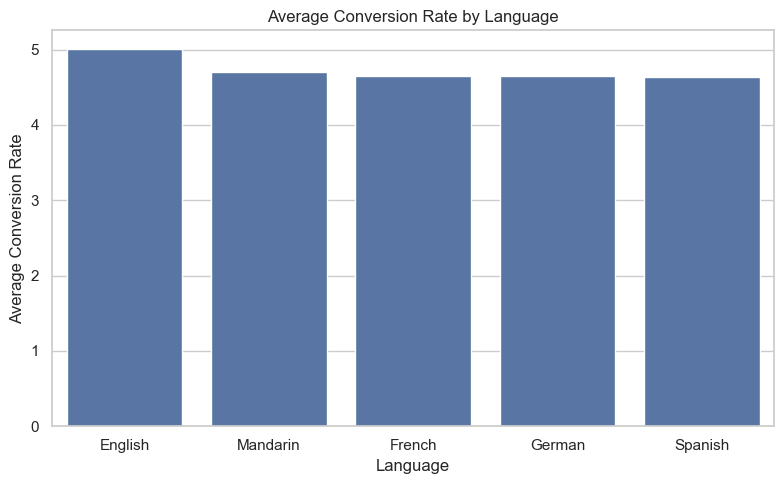

In [16]:
# Average Conversion Rate by Language

lang_conv = (
    df.groupby("Language")["Conversion_Rate"]
    .mean()
    .reset_index()
    .sort_values("Conversion_Rate", ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=lang_conv,
    x="Language",
    y="Conversion_Rate"
)

plt.title("Average Conversion Rate by Language")
plt.xlabel("Language")
plt.ylabel("Average Conversion Rate")
plt.tight_layout()
plt.show()

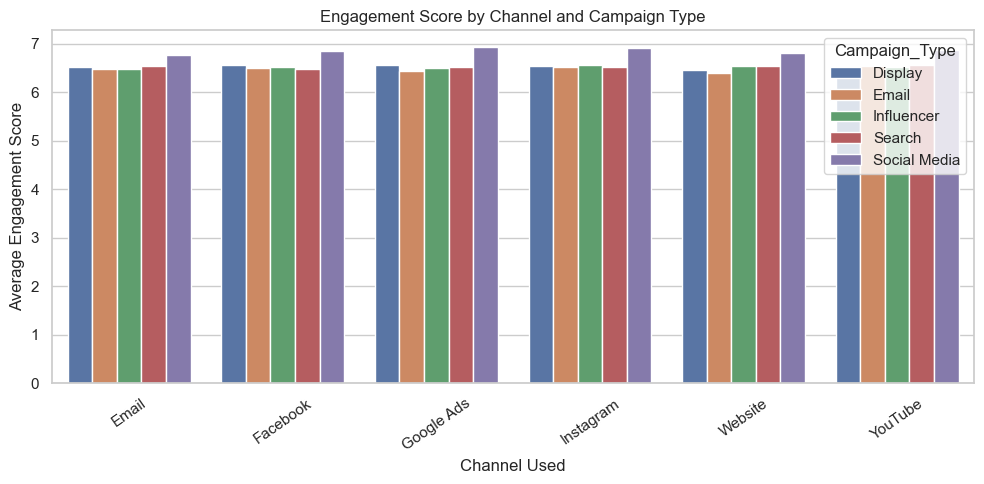

In [17]:
# Channel Effectiveness Analysis
# Engagement Score by Channel and Campaign Type

channel_eng = (
    df.groupby(
        ["Channel_Used", "Campaign_Type"]
    )["Engagement_Score"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=channel_eng,
    x="Channel_Used",
    y="Engagement_Score",
    hue="Campaign_Type"
)

plt.title("Engagement Score by Channel and Campaign Type")
plt.xlabel("Channel Used")
plt.ylabel("Average Engagement Score")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

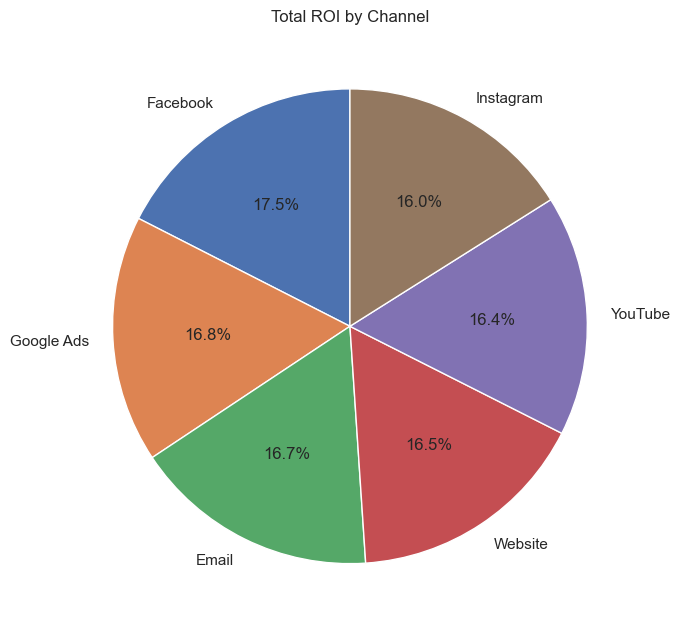

In [18]:
# Total ROI by Channel

roi_channel = (
    df.groupby("Channel_Used")["ROI"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 7))

plt.pie(
    roi_channel,
    labels=roi_channel.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Total ROI by Channel")
plt.tight_layout()
plt.show()

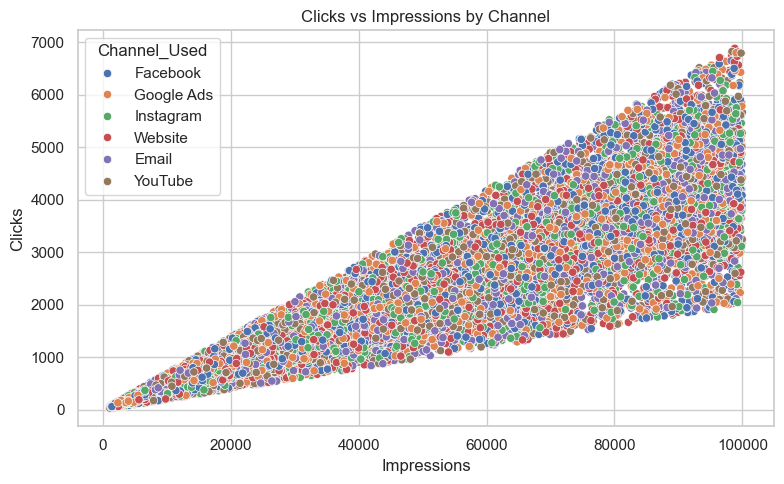

In [19]:
# Clicks vs Impressions by Channel

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Impressions",
    y="Clicks",
    hue="Channel_Used"
)

plt.title("Clicks vs Impressions by Channel")
plt.xlabel("Impressions")
plt.ylabel("Clicks")
plt.tight_layout()
plt.show()

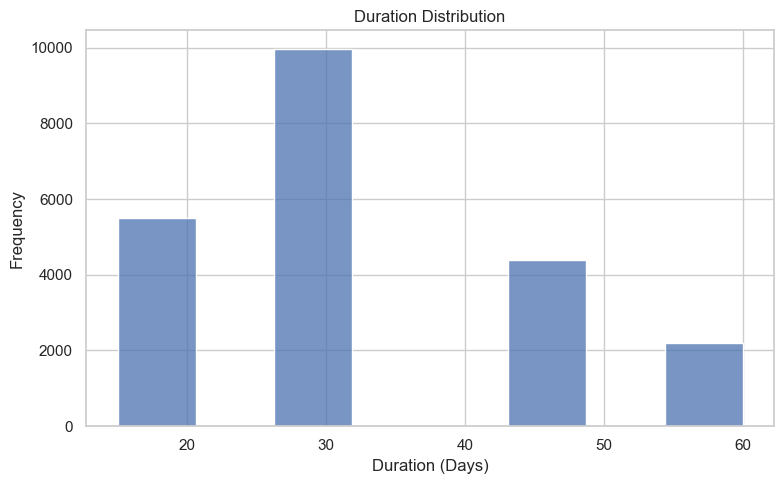

In [20]:
# Time-Based Analysis
# Duration Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Duration_Days",
    bins=8
)

plt.title("Duration Distribution")
plt.xlabel("Duration (Days)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

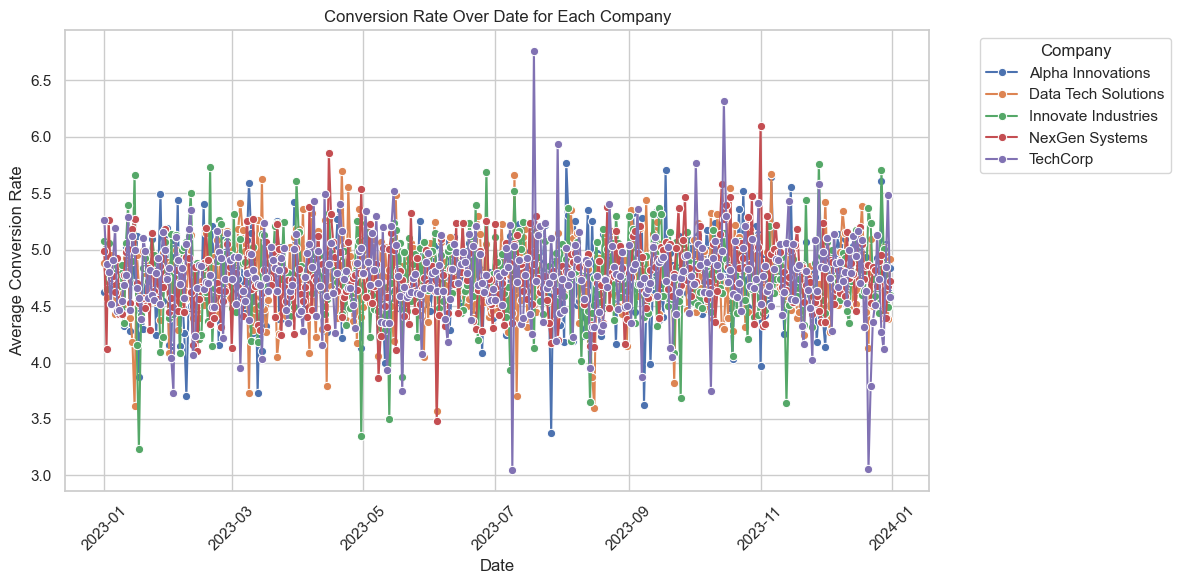

In [21]:
# Conversion Rate Over Date for Each Company

daily_company_conversion = (
    df.groupby(
        ["Date", "Company"]
    )["Conversion_Rate"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=daily_company_conversion,
    x="Date",
    y="Conversion_Rate",
    hue="Company",
    marker="o"
)

plt.title("Conversion Rate Over Date for Each Company")
plt.xlabel("Date")
plt.ylabel("Average Conversion Rate")
plt.xticks(rotation=45)

plt.legend(
    title="Company",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

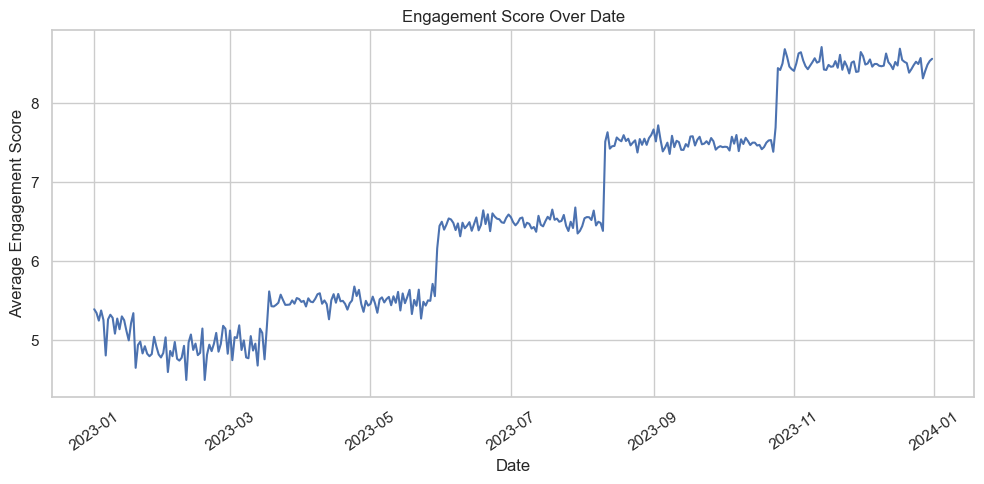

In [22]:
# Engagement Score Trend Over Date

daily_engagement = (
    df.groupby("Date")["Engagement_Score"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=daily_engagement,
    x="Date",
    y="Engagement_Score"
)

plt.title("Engagement Score Over Date")
plt.xlabel("Date")
plt.ylabel("Average Engagement Score")
plt.xticks(rotation=35)

plt.tight_layout()
plt.show()

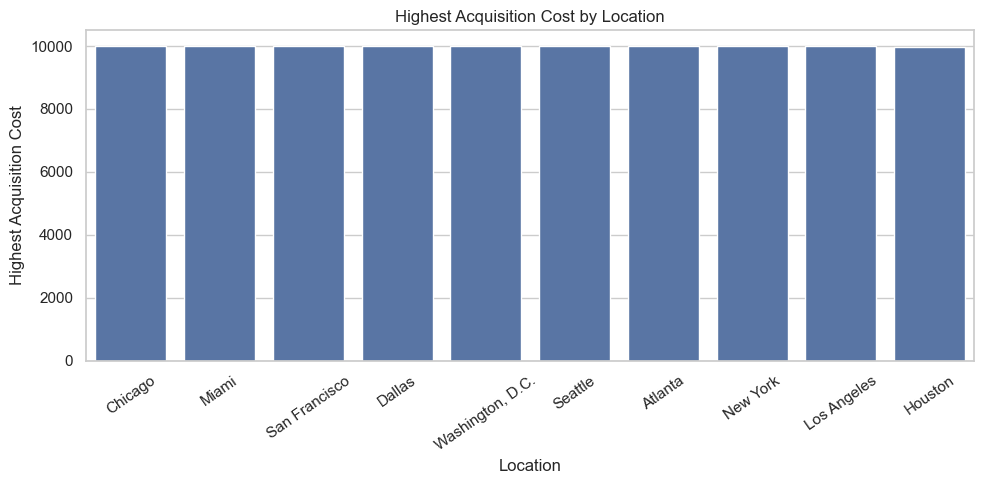

Location with highest Acquisition Cost:
Location            Chicago
Acquisition_Cost       9999
Name: 1, dtype: object


In [23]:
# Geographic Analysis
# Highest Acquisition Cost by Location

location_highest_cost = (
    df.groupby("Location")["Acquisition_Cost"]
    .max()
    .reset_index()
    .sort_values("Acquisition_Cost", ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=location_highest_cost,
    x="Location",
    y="Acquisition_Cost"
)

plt.title("Highest Acquisition Cost by Location")
plt.xlabel("Location")
plt.ylabel("Highest Acquisition Cost")
plt.xticks(rotation=35)

plt.tight_layout()
plt.show()

print("Location with highest Acquisition Cost:")
print(location_highest_cost.iloc[0])

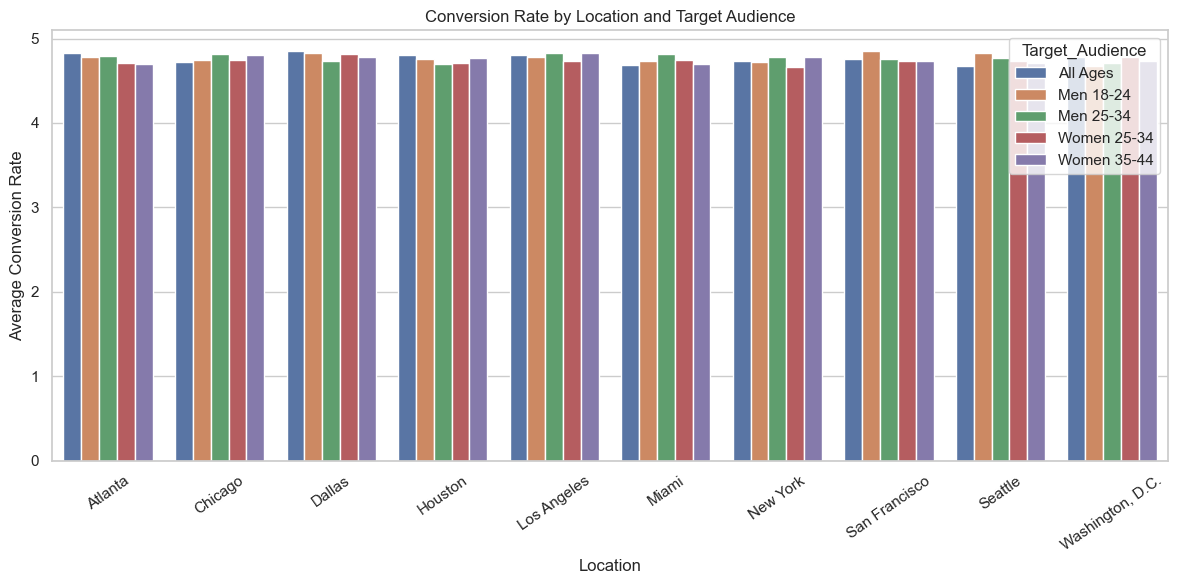

In [24]:
# Conversion Rate by Location and Target Audience

loc_aud = (
    df.groupby(
        ["Location", "Target_Audience"]
    )["Conversion_Rate"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=loc_aud,
    x="Location",
    y="Conversion_Rate",
    hue="Target_Audience"
)

plt.title("Conversion Rate by Location and Target Audience")
plt.xlabel("Location")
plt.ylabel("Average Conversion Rate")
plt.xticks(rotation=35)

plt.tight_layout()
plt.show()

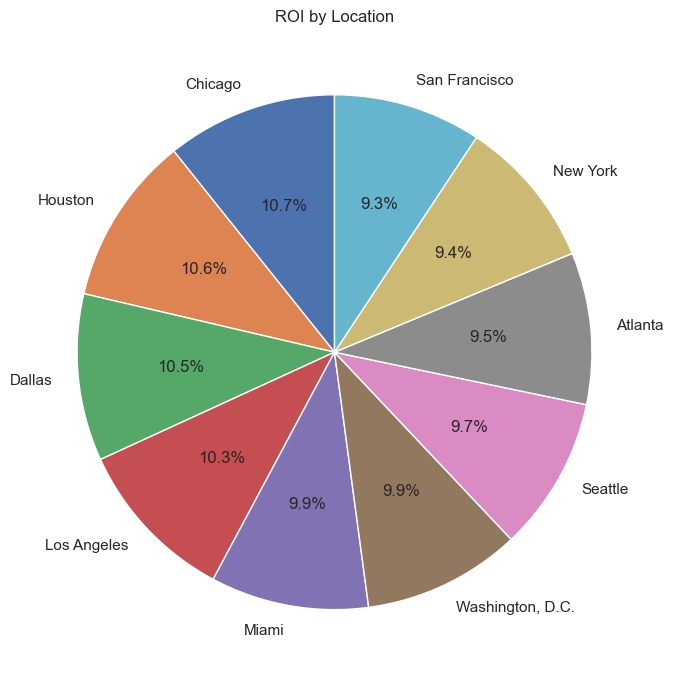

In [25]:
# ROI by Location

roi_location = (
    df.groupby("Location")["ROI"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 7))

plt.pie(
    roi_location,
    labels=roi_location.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("ROI by Location")
plt.tight_layout()
plt.show()

In [26]:
# Final Insights and Recommendations

highest_roi_company = (
    df.groupby("Company")["ROI"]
    .mean()
    .idxmax()
)

highest_conversion_channel = (
    df.groupby("Channel_Used")["Conversion_Rate"]
    .mean()
    .idxmax()
)

highest_total_roi_channel = (
    df.groupby("Channel_Used")["ROI"]
    .sum()
    .idxmax()
)

best_language = (
    df.groupby("Language")["Conversion_Rate"]
    .mean()
    .idxmax()
)

highest_acquisition_cost_location = (
    df.groupby("Location")["Acquisition_Cost"]
    .max()
    .idxmax()
)

correlation = df[
    ["Engagement_Score", "Conversion_Rate"]
].corr()

print("Highest average ROI company:", highest_roi_company)
print("Highest conversion channel:", highest_conversion_channel)
print("Highest total ROI channel:", highest_total_roi_channel)
print("Best language by conversion:", best_language)
print(
    "Location with highest Acquisition Cost:",
    highest_acquisition_cost_location
)

print("\nCorrelation between Engagement Score and Conversion Rate:")
print(correlation)

Highest average ROI company: Alpha Innovations
Highest conversion channel: Facebook
Highest total ROI channel: Facebook
Best language by conversion: English
Location with highest Acquisition Cost: Chicago

Correlation between Engagement Score and Conversion Rate:
                  Engagement_Score  Conversion_Rate
Engagement_Score          1.000000         0.010546
Conversion_Rate           0.010546         1.000000


In [ ]:
## Conclusion

The marketing campaign dataset was analyzed using descriptive statistics and exploratory data analysis.

The analysis compared campaign performance across companies, campaign types, channels, customer segments, languages, dates, and locations.

Based on the analysis, Facebook showed strong conversion and ROI performance, Alpha Innovations had the highest average ROI, English campaigns had the best average conversion rate, and Chicago had the highest acquisition cost.

These insights can help improve future marketing strategies by focusing on high-performing channels, monitoring acquisition costs, and targeting customer segments with stronger conversion rates.